### End to End Machine learning project from the book 
### 'Hands on machine learning using scikitlearn, keras and tensorflow' by Aerelon Geron.

In [5]:
# Download the data.

In [1]:
from pathlib import Path
import pandas as pd
import tarfile 
import urllib.request

In [2]:
def load_housing_data():
    tarball_path = Path("datasets/housing.tgz")
    if not tarball_path.is_file():
        Path("datasets").mkdir(parents = True, exist_ok = True)
        url = "https://github.com/ageron/data/raw/main/housing.tgz"
        urllib.request.urlretrieve(url, tarball_path)
        with tarfile.open(tarball_path) as housing_tarball:
            housing_tarball.extractall(path = "datasets")
    return pd.read_csv(Path("datasets/housing/housing.csv") )

housing = load_housing_data()    
#review this code chunk further.

In [3]:
housing.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
housing.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [7]:
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [8]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


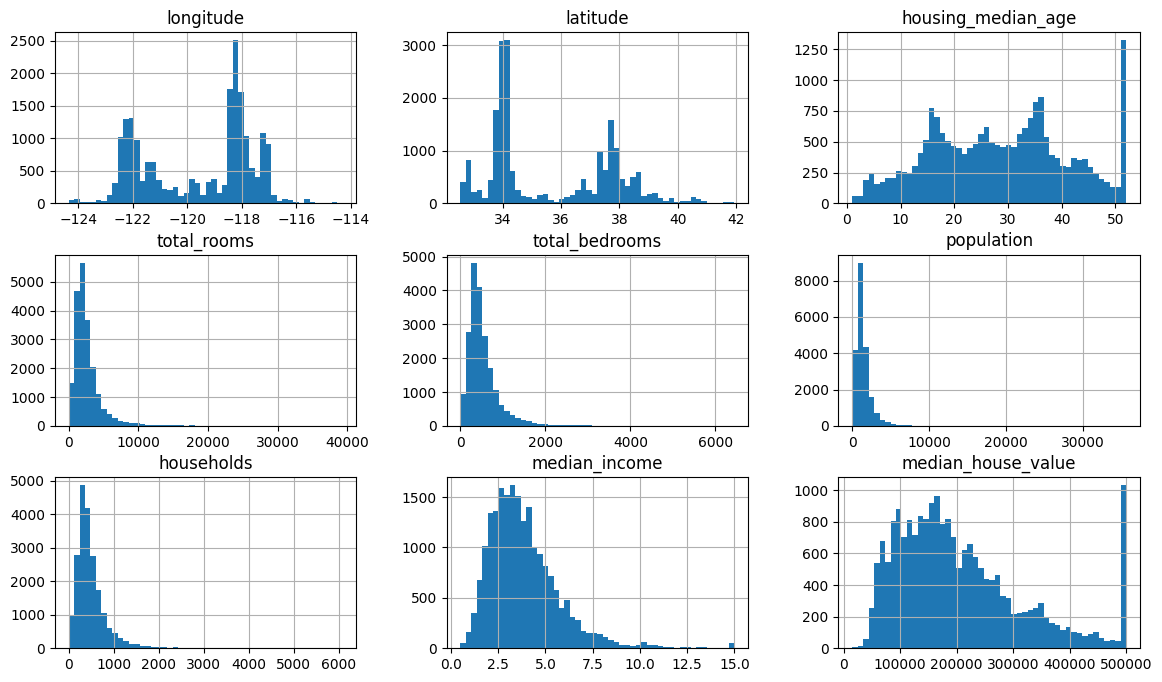

In [9]:
import matplotlib.pyplot as plt

housing.hist(bins= 50, figsize = (14,8) )
plt.show()

- median income attribute is not expressed in US dollars. The data has been scaled and capped at 15 for higher incomes and 0.5 for lower incomes.
- median house value and housing median age were also capped as we can observe at the end of the graph (any house with price greater than 500000 are capped).
  


In [14]:
import numpy as np
np.random.seed(42)

def shuffle_and_split_data(data, test_ratio):
    shuffled_indices = np.random.permutation(len(data))
    test_size = int(len(data) * test_ratio )
    test_indices = shuffled_indices[:test_size]
    train_indices = shuffled_indices[test_size:]
    return data.iloc[train_indices], data.iloc[test_indices]

train_data, test_data = shuffle_and_split_data(housing, 0.2) # 20% testing data.

In [15]:
len(train_data)

16512

In [16]:
len(test_data)

4128

In [17]:
from zlib import crc32

def is_id_in_test_set(identifier, test_ratio):
    return crc32(np.int64(identifier)) < test_ratio * 2**32 ## didn't really understand this condition.

def split_data_with_id_hash(data, test_ratio, id_column):
    ids = data[id_column]
    in_test_set = ids.apply(lambda id_: is_id_in_test_set(id_, test_ratio))
    return data.loc[~in_test_set], data.loc[in_test_set]
## review this code chunk further.

In [18]:
# the housing dataset does not have an identifier column.
# One way we can use index as the ID:
housing_with_id = housing.reset_index()
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "index")

# Or, either we can define a ID column using an attribute which is unique for each instance (comb of lat & long is unique)
housing_with_id["id"] = housing["longitude"] *1000 + housing["latitude"]
train_set, test_set = split_data_with_id_hash(housing_with_id, 0.2, "id")

In [19]:
## train & test split using sklearn
from sklearn.model_selection import train_test_split

train_set , test_set = train_test_split(housing, test_size = 0.2, random_state = 42)


In [20]:
test_set.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
20046,-122.38,40.67,10.0,2281.0,444.0,1274.0,438.0,2.2120,65600.0,INLAND
3024,-118.37,33.83,35.0,1207.0,207.0,601.0,213.0,4.7308,353400.0,<1H OCEAN
15663,-117.24,32.72,39.0,3089.0,431.0,1175.0,432.0,7.5925,466700.0,NEAR OCEAN
20484,-118.44,34.05,18.0,4780.0,1192.0,1886.0,1036.0,4.4674,500001.0,<1H OCEAN
9814,-118.44,34.18,33.0,2127.0,414.0,1056.0,391.0,4.3750,286100.0,<1H OCEAN


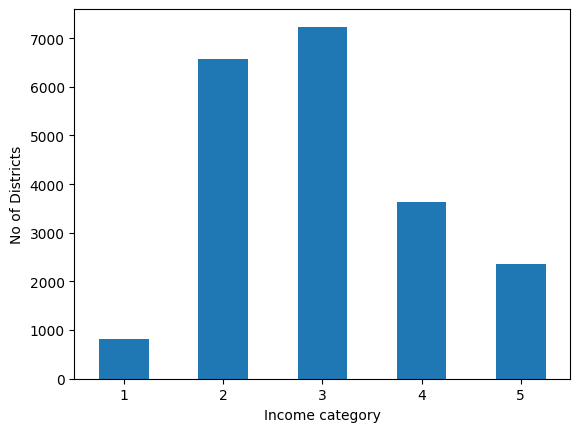

In [21]:
# Creating income category:
housing["income_cat"] = pd.cut(housing["median_income"],
                               bins = [0, 1.5, 3.0, 4.5, 6, np.inf],
                               labels = [1,2,3,4,5] )
housing["income_cat"].value_counts() \
                    .sort_index() \
                    .plot.bar(rot = 0)
plt.xlabel("Income category")
plt.ylabel("No of Districts")
plt.show()

### Stratifed train_test split
- StratifedShuffleSplit provides train/test indices to split data by stratifed sampling.

In [22]:
from sklearn.model_selection import StratifiedShuffleSplit

splitter = StratifiedShuffleSplit(n_splits = 10, test_size = 0.2, random_state = 42)
strat_splits = []
for train_index, test_index in splitter.split(housing, housing["income_cat"]):
    strat_train_set = housing.iloc[train_index]
    strat_test_set = housing.iloc[test_index]
    strat_splits.append([strat_train_set, strat_test_set])

strat_train_set, strat_test_set = strat_splits[2]

In [17]:
strat_test_set["income_cat"].value_counts() / len(strat_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

### Another shorter way to split data stratifically.

In [23]:
strat_train_set , strat_test_set = train_test_split(housing, 
                                                    random_state = 42,
                                                    test_size = 0.2,
                                                    stratify = housing["income_cat"] )


In [24]:
strat_test_set["income_cat"].value_counts() / len(strat_test_set)

income_cat
3    0.350533
2    0.318798
4    0.176357
5    0.114341
1    0.039971
Name: count, dtype: float64

In [25]:
## compairing different income category for random and stratified sampling:
def income_cat_to_perc(data):
    return data["income_cat"].value_counts() / len(data["income_cat"])

train_set, test_set = train_test_split(housing, test_size = 0.2, random_state = 42)

compare_income_cat = pd.DataFrame({
                "Overall %" : income_cat_to_perc(housing),
                "Stratified %" : income_cat_to_perc(strat_test_set),
                "Random %" : income_cat_to_perc(test_set) } ).sort_index()

compare_income_cat["Stratified Error %"] = (compare_income_cat["Stratified %"] - compare_income_cat["Overall %"] )
compare_income_cat["Random Error %"] = (compare_income_cat["Random %"] - compare_income_cat["Overall %"] )

compare_income_cat.index.name = "Income Category"
compare_income_cat *100

,Overall %,Stratified %,Random %,Stratified Error %,Random Error %
Income Category,,,,,
1,3.982558,3.997093,4.239341,0.014535,0.256783
2,31.884690,31.879845,30.741279,-0.004845,-1.143411
3,35.058140,35.053295,34.520349,-0.004845,-0.537791
4,17.630814,17.635659,18.410853,0.004845,0.780039
5,11.443798,11.434109,12.088178,-0.009690,0.644380


In [26]:
for set_ in (strat_train_set, strat_test_set):
    set_.drop("income_cat", axis =1 , inplace = True)

### Explore and visualize to Gain insights:

In [22]:
housing = strat_train_set.copy()

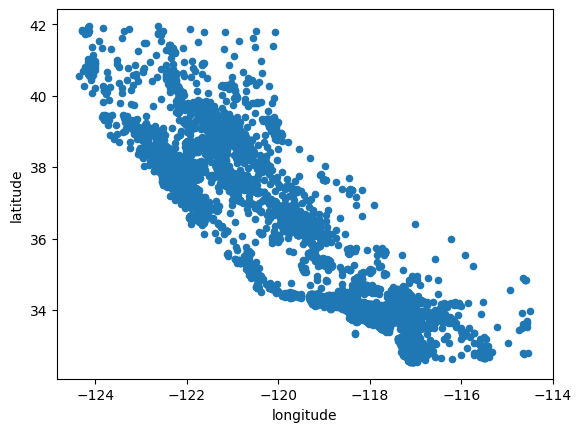

In [23]:
housing.plot(kind = "scatter",
             x = "longitude",
             y = "latitude")
plt.show()

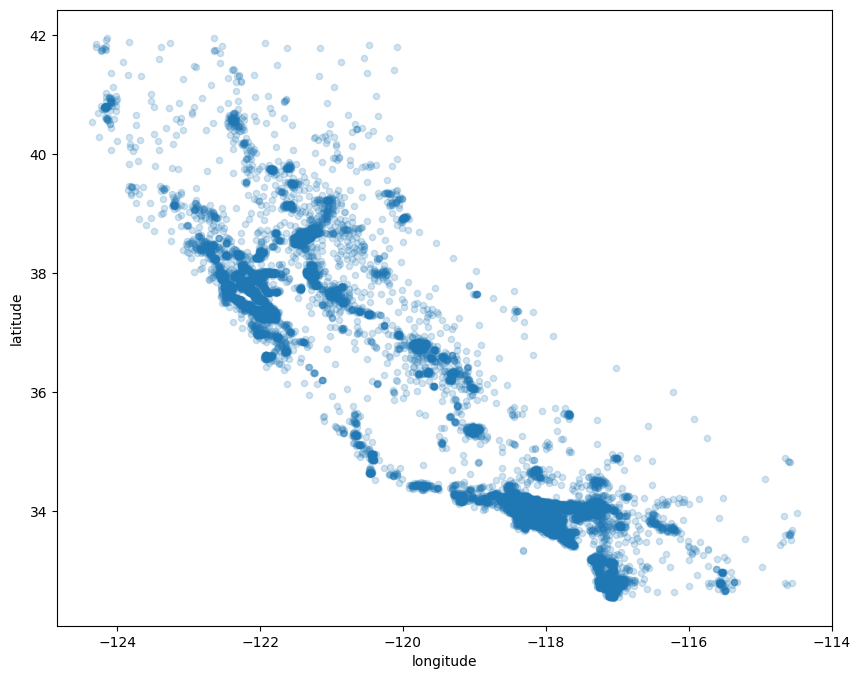

In [24]:
housing.plot(kind = "scatter",
             x = "longitude",
             y = "latitude",
            alpha = 0.2,
            figsize = (10, 8))
plt.show()

In [25]:
housing["population"]/100

13096    15.76
14973     6.66
3785      5.62
14689    18.45
20507    19.12
         ...  
14207     9.38
13105    14.19
19301    28.14
19121    17.25
19888     6.82
Name: population, Length: 16512, dtype: float64

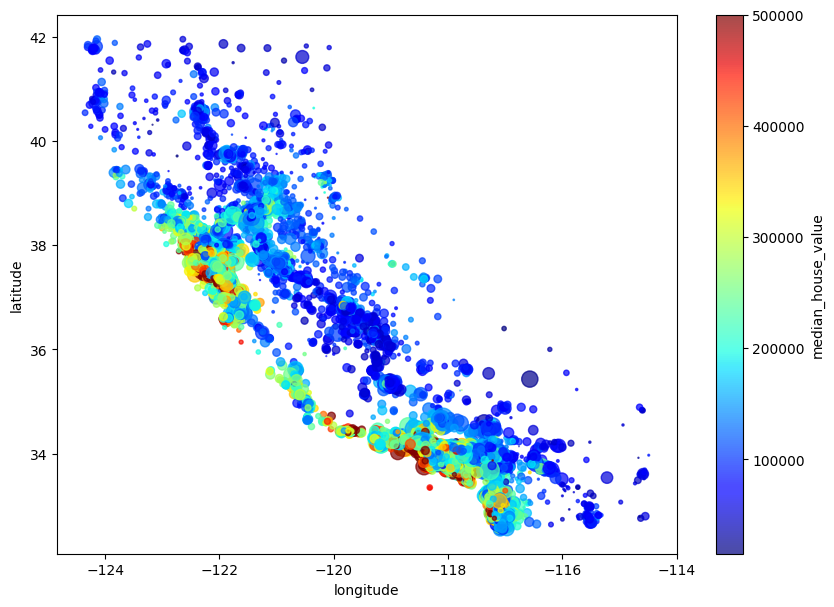

In [26]:
housing.plot(kind = "scatter", x = "longitude", y = "latitude", alpha = 0.7,
             s = housing["population"] / 50, 
             c = "median_house_value", cmap = "jet", colorbar = True,
             legend=True, sharex=False, figsize = (10,7) )
plt.show()

### looking for correlations of median house value with other variables.

In [27]:
corr_matrix = housing.corr(numeric_only = True)
corr_matrix

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
longitude,1.000000,-0.924664,-0.108197,0.044568,0.069608,0.099773,0.055310,-0.015176,-0.045967
latitude,-0.924664,1.000000,0.011173,-0.036100,-0.066983,-0.108785,-0.071035,-0.079809,-0.144160
housing_median_age,-0.108197,0.011173,1.000000,-0.361262,-0.320451,-0.296244,-0.302916,-0.119034,0.105623
total_rooms,0.044568,-0.036100,-0.361262,1.000000,0.930380,0.857126,0.918484,0.198050,0.134153
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686
population,0.099773,-0.108785,-0.296244,0.857126,0.877747,1.000000,0.907222,0.004834,-0.024650
households,0.055310,-0.071035,-0.302916,0.918484,0.979728,0.907222,1.000000,0.013033,0.065843
median_income,-0.015176,-0.079809,-0.119034,0.198050,-0.007723,0.004834,0.013033,1.000000,0.688075
median_house_value,-0.045967,-0.144160,0.105623,0.134153,0.049686,-0.024650,0.065843,0.688075,1.000000


In [28]:
corr_matrix['median_house_value'].sort_values(ascending = False)

median_house_value    1.000000
median_income         0.688380
total_rooms           0.137455
housing_median_age    0.102175
households            0.071426
total_bedrooms        0.054635
population           -0.020153
longitude            -0.050859
latitude             -0.139584
Name: median_house_value, dtype: float64

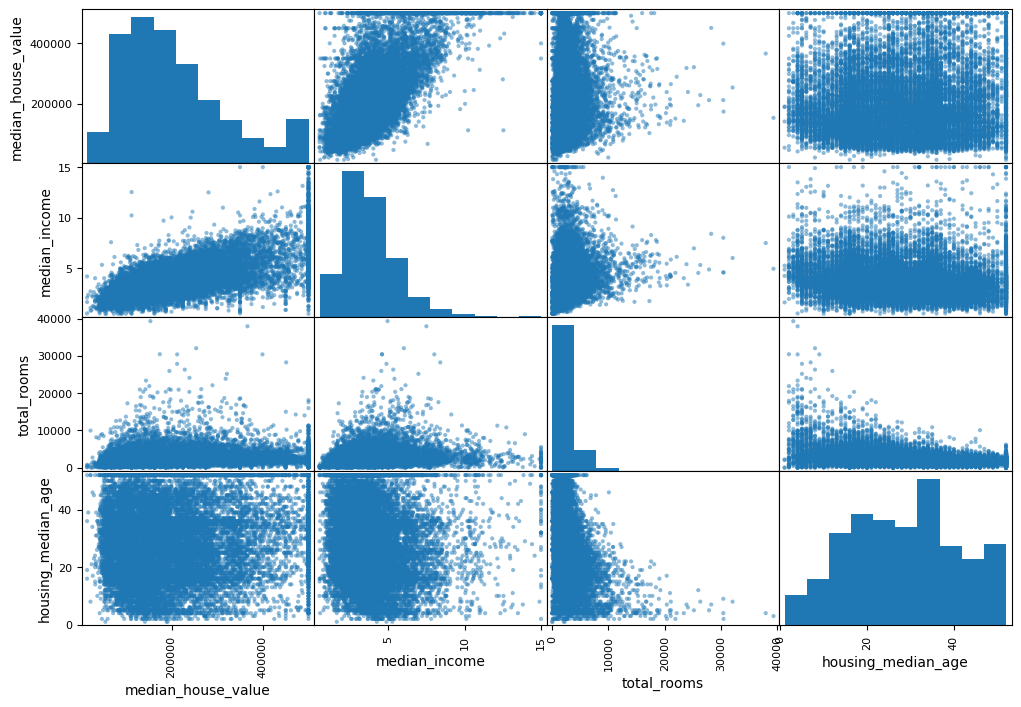

In [29]:
# drawing scatter matrix
from pandas.plotting import scatter_matrix

attributes = ["median_house_value", "median_income", "total_rooms", "housing_median_age"]
scatter_matrix(housing[attributes], figsize = (12,8))

plt.show()

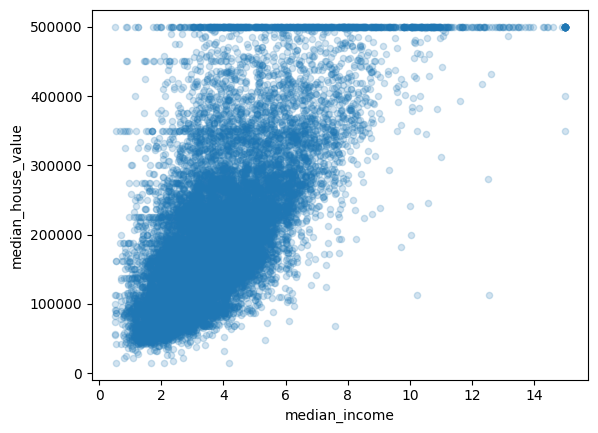

In [30]:
housing.plot(kind = 'scatter', 
             x = "median_income",
             y = "median_house_value", 
             alpha = 0.2)
plt.show()

#### Creating new columns by transformation:

In [28]:
housing["rooms_per_house"] = housing["total_rooms"] / housing["households"]
housing["bedrooms_ratio"] = housing["total_bedrooms"] / housing["total_rooms"]
housing["people_per_house"] = housing["population"] / housing["households"]

corr_matrix = housing.corr(numeric_only = True)
corr_matrix["median_house_value"].sort_values(ascending= True)

bedrooms_ratio       -0.255880
latitude             -0.144160
longitude            -0.045967
population           -0.024650
people_per_house     -0.023737
total_bedrooms        0.049686
households            0.065843
housing_median_age    0.105623
total_rooms           0.134153
rooms_per_house       0.151948
median_income         0.688075
median_house_value    1.000000
Name: median_house_value, dtype: float64

### Prepare the data for ML algorithms 

In [36]:
# separating predictor and response variable
housing = strat_train_set.drop("median_house_value", axis = 1)
housing_labels = strat_train_set["median_house_value"].copy()

#### Replacing missing values
- There are several ways to replace missing observations --> replace with 0, mean/median value, forward fill or interpolation .

In [37]:
# replacing with median values:
housing.isna().sum()

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        168
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64

In [38]:
median = housing["total_bedrooms"].median()
housing["total_bedrooms"].fillna(median, inplace = True)

In [39]:
housing.isna().sum()

longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
ocean_proximity       0
dtype: int64

In [40]:
# another way to replace missing value with median/mean value is to use SimpleImputer class from scikit learn:
from sklearn.impute import SimpleImputer

imputer = SimpleImputer(strategy = "median")
housing_num = housing.select_dtypes(include = [np.number])
imputer.fit(housing_num)
imputer.statistics_ #it gives the median value of each numerical column as output

array([-118.51  ,   34.26  ,   29.    , 2125.    ,  434.    , 1167.    ,
        408.    ,    3.5385])

In [41]:
X = imputer.transform(housing_num)
# Scikit-learn transformer output numpy arrays.
housing_tr = pd.DataFrame(X, 
                          columns = housing_num.columns,
                          index = housing_num.index)

In [42]:
# housing_tr.isna().sum()
housing_tr.shape

(16512, 8)

#### Handling Text and Categorical Attributes:

In [43]:
from sklearn.preprocessing import OneHotEncoder

housing_cat = housing[["ocean_proximity"]]
cat_encoder = OneHotEncoder(sparse_output = False)
housing_cat_1hot = cat_encoder.fit_transform(housing_cat)
housing_cat_1hot

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

In [44]:
housing_cat_1hot

array([[0., 0., 0., 1., 0.],
       [1., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0.],
       ...,
       [0., 0., 0., 0., 1.],
       [1., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1.]])

In [45]:
cat_encoder.categories_

[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
       dtype=object)]

In [46]:
df_test = pd.DataFrame( {"ocean_proximity" : ["ISLAND", "NEAR BAY"] } )
pd.get_dummies(df_test)
# one major advantage of OneHotEncoder over get_dummies is that it remembers which categories it was trained on.


,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY
0,True,False
1,False,True


In [47]:
cat_encoder.transform(df_test)

array([[0., 0., 1., 0., 0.],
       [0., 0., 0., 1., 0.]])

In [48]:
df_test_unknown = pd.DataFrame({"ocean_proximity": ["<2H OCEAN", "ISLAND"]})
pd.get_dummies(df_test_unknown)

,ocean_proximity_<2H OCEAN,ocean_proximity_ISLAND
0,True,False
1,False,True


In [49]:
cat_encoder.handle_unknown = "ignore"
cat_encoder.transform(df_test_unknown)

array([[0., 0., 0., 0., 0.],
       [0., 0., 1., 0., 0.]])

In [50]:
cat_encoder.feature_names_in_

array(['ocean_proximity'], dtype=object)

In [51]:
cat_encoder.get_feature_names_out()

array(['ocean_proximity_<1H OCEAN', 'ocean_proximity_INLAND',
       'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY',
       'ocean_proximity_NEAR OCEAN'], dtype=object)

In [52]:
 pd.DataFrame(cat_encoder.transform(df_test_unknown),
                         columns=cat_encoder.get_feature_names_out(),
                         index = df_test_unknown.index )

,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0.0,0.0,0.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0


## Feature scaling and Transformation:

In [56]:
# normalization
from sklearn.preprocessing import MinMaxScaler

min_max_scaler = MinMaxScaler(feature_range= (-1, 1))
housing_num_min_max_sclaed = min_max_scaler.fit_transform(housing_num)
housing_num_min_max_sclaed

array([[-0.60851927,  0.11702128,  1.        , ..., -0.80701754,
        -0.61433638, -0.7794789 ],
       [ 0.21095335, -0.66170213,  0.52941176, ..., -0.91866029,
        -0.86708979, -0.22929339],
       [-0.51926978,  0.23617021,  0.25490196, ..., -0.93141946,
        -0.92458466, -0.73336919],
       ...,
       [ 0.47870183, -0.99148936, -0.52941176, ..., -0.65513434,
        -0.71663244, -0.50873781],
       [ 0.20689655, -0.6787234 ,  0.41176471, ..., -0.78873758,
        -0.68751167, -0.49716556],
       [-0.60649087,  0.08723404,  0.68627451, ..., -0.91669734,
        -0.92122457, -0.61608805]])

In [58]:
# standardization:
from sklearn.preprocessing import StandardScaler

std_scaler = StandardScaler()
housing_num_std_scaled = std_scaler.fit_transform(housing_num)
housing_num_std_scaled

array([[-1.42303652,  1.0136059 ,  1.86111875, ...,  0.13746004,
         1.39481249, -0.93649149],
       [ 0.59639445, -0.702103  ,  0.90762971, ..., -0.69377062,
        -0.37348471,  1.17194198],
       [-1.2030985 ,  1.27611874,  0.35142777, ..., -0.78876841,
        -0.77572662, -0.75978881],
       ...,
       [ 1.25620853, -1.42870103, -1.23772062, ...,  1.26829911,
         0.67913534,  0.1010487 ],
       [ 0.58639727, -0.73960483,  0.66925745, ...,  0.27356264,
         0.88286825,  0.14539615],
       [-1.41803793,  0.94797769,  1.22545939, ..., -0.67915557,
        -0.75221898, -0.31034135]])

In [64]:
# simple linear regression model:
from sklearn.linear_model import LinearRegression

target_scaler = StandardScaler()
scaled_labels = target_scaler.fit_transform(housing_labels.to_frame())

model = LinearRegression()
model.fit(housing_num[["median_income"]], scaled_labels)


LinearRegression()

In [65]:
new_data = housing_num[["median_income"]].iloc[:5]
y_predict_scaled = model.predict(new_data)
y_predict = target_scaler.inverse_transform(y_predict_scaled)


In [68]:
y_predict

array([[131997.15275877],
       [299359.35844434],
       [146023.37185694],
       [138840.33653057],
       [192016.61557639]])

In [69]:
from sklearn.compose import TransformedTargetRegressor

model = TransformedTargetRegressor(LinearRegression(),
                                    transformer = StandardScaler())
model.fit(housing[["median_income"]],
          housing_labels)
predictions = model.predict(new_data)
predictions

array([131997.15275877, 299359.35844434, 146023.37185694, 138840.33653057,
       192016.61557639])

## Custom Transfromers

In [73]:
i = 0
while i<= 100:
    print(i)
    i +=1

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99
100
